In [1]:
import glob
import re
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

## load

In [2]:


base_dir = "/data/oacd/geog0121/UKESM1_summary_files/SMILE_members"

def parse_ensemble_id(fname):
    match = re.search(r"UKESM1-r(\d+)_", fname)
    if not match:
        raise ValueError(f"Could not parse ensemble ID in filename: {fname}")
    return int(match.group(1))

def load_ukesm1_scenario(scenario):
    end_year = "2014" if scenario == "historical" else "2100"
    pattern = f"{base_dir}/UKESM1-r*_{scenario}_1850-1900.cvdp_data.1850-{end_year}.nc"
    files = sorted(glob.glob(pattern))

    print(f"\nScenario: {scenario}")
    print("Number of files found:", len(files))

    if len(files) == 0:
        raise ValueError(f"No files found for scenario {scenario}")

    # first pass: inspect variables in each file
    var_sets = []
    for f in files:
        ds = xr.open_dataset(f, decode_times=False)
        var_sets.append(set(ds.data_vars))

    common_vars = set.intersection(*var_sets)
    print(f"Number of common variables across all members: {len(common_vars)}")

    # optional: show variables missing in some files
    union_vars = set.union(*var_sets)
    missing_somewhere = sorted(union_vars - common_vars)
    print(f"Variables missing in at least one member: {len(missing_somewhere)}")
    if len(missing_somewhere) > 0:
        print("Example missing variables:", missing_somewhere[:20])

    common_vars = sorted(common_vars)

    # second pass: load only common variables
    ds_list = []
    ens_ids = []

    for f in files:
        ens_id = parse_ensemble_id(f)
        print(f"  Loading ensemble r{ens_id}")

        ds = xr.open_dataset(f, decode_times=False, chunks={})

        # keep only variables shared by all files
        ds = ds[common_vars]

        # drop nuisance coords if they appear
        for name in ["i", "j"]:
            if name in ds.coords or name in ds.variables:
                ds = ds.drop_vars(name, errors="ignore")

        ds = ds.expand_dims({"ensemble": [ens_id]})
        ds_list.append(ds)
        ens_ids.append(ens_id)

    ds_out = xr.concat(
        ds_list,
        dim="ensemble",
        coords="minimal",
        compat="override"
    )

    print(f"Loaded {scenario} with ensemble members: {ens_ids}")
    return ds_out

UKESM1_historical = load_ukesm1_scenario("historical")
UKESM1_ssp126     = load_ukesm1_scenario("ssp126")
UKESM1_ssp245     = load_ukesm1_scenario("ssp245")
UKESM1_ssp370     = load_ukesm1_scenario("ssp370")


Scenario: historical
Number of files found: 16
Number of common variables across all members: 644
Variables missing in at least one member: 0
  Loading ensemble r10
  Loading ensemble r11
  Loading ensemble r12
  Loading ensemble r16
  Loading ensemble r17
  Loading ensemble r18
  Loading ensemble r19
  Loading ensemble r1
  Loading ensemble r2
  Loading ensemble r3
  Loading ensemble r4
  Loading ensemble r5
  Loading ensemble r6
  Loading ensemble r7
  Loading ensemble r8
  Loading ensemble r9
Loaded historical with ensemble members: [10, 11, 12, 16, 17, 18, 19, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Scenario: ssp126
Number of files found: 16
Number of common variables across all members: 603
Variables missing in at least one member: 41
Example missing variables: ['amoc_amo_lag_cor', 'amoc_mean_ann', 'amoc_pattern_ann', 'amoc_pr_regression_ann', 'amoc_spectra_ann', 'amoc_sst_regression_ann', 'amoc_stddev_ann', 'amoc_tas_regression_ann', 'amoc_timeseries_ann', 'sic_nh_spatialmean_ann', 'sic_nh_

## list

In [3]:
# variables in specific scenarios
ds = UKESM1_historical   # or replace "UKESM1_historical" to "UKESM1_ssp126", "UKESM1_ssp245", "UKESM1_ssp370" to see variables in other scenarios

print("Number of variables:", len(ds.data_vars))
for v in ds.data_vars:
    print(v)

Number of variables: 644
amm_pattern_mon
amm_pr_regression_mon
amm_spectra
amm_tas_regression_mon
amm_timeseries_mon
amo_pattern_lowpass_mon
amo_pattern_mon
amo_pr_regression_lowpass_mon
amo_pr_regression_mon
amo_spectra
amo_tas_regression_lowpass_mon
amo_tas_regression_mon
amo_timeseries_lowpass_mon
amo_timeseries_mon
amoc_amo_lag_cor
amoc_mean_ann
amoc_pattern_ann
amoc_pr_regression_ann
amoc_spectra_ann
amoc_sst_regression_ann
amoc_stddev_ann
amoc_tas_regression_ann
amoc_timeseries_ann
atl3_pattern_mon
atl3_pr_regression_mon
atl3_spectra
atl3_tas_regression_mon
atl3_timeseries_mon
atlantic_meridional_mode
atlantic_nino
date
east_eq_indian_ocean
indian_ocean_dipole
iod_pattern_mon
iod_pr_regression_mon
iod_spectra
iod_tas_regression_mon
iod_timeseries_mon
ipcc_ARO_pr
ipcc_ARO_tas
ipcc_ARP_pr
ipcc_ARP_tas
ipcc_ARS_pr
ipcc_ARS_tas
ipcc_BOB_pr
ipcc_BOB_tas
ipcc_CAF_pr
ipcc_CAF_tas
ipcc_CAR_lnd_pr
ipcc_CAR_lnd_tas
ipcc_CAR_ocn_pr
ipcc_CAR_ocn_tas
ipcc_CAU_pr
ipcc_CAU_tas
ipcc_CNA_pr
ipcc_

In [4]:
# common variables
all_scenarios = [UKESM1_historical, UKESM1_ssp126, UKESM1_ssp245, UKESM1_ssp370]

common_vars = set(all_scenarios[0].data_vars).intersection(*[set(ds.data_vars) for ds in all_scenarios[1:]])
common_vars_list = sorted(list(common_vars))

# Print 
print(f"Number of common variables: {len(common_vars_list)}\n")
for v in common_vars_list:
    print(v)

Number of common variables: 390

date
ipcc_ARO_pr
ipcc_ARO_tas
ipcc_ARP_pr
ipcc_ARP_tas
ipcc_ARS_pr
ipcc_ARS_tas
ipcc_BOB_pr
ipcc_BOB_tas
ipcc_CAF_pr
ipcc_CAF_tas
ipcc_CAR_lnd_pr
ipcc_CAR_lnd_tas
ipcc_CAR_ocn_pr
ipcc_CAR_ocn_tas
ipcc_CAU_pr
ipcc_CAU_tas
ipcc_CNA_pr
ipcc_CNA_tas
ipcc_EAN_pr
ipcc_EAN_tas
ipcc_EAO_pr
ipcc_EAO_tas
ipcc_EAS_pr
ipcc_EAS_tas
ipcc_EAU_pr
ipcc_EAU_tas
ipcc_ECA_pr
ipcc_ECA_tas
ipcc_EEU_pr
ipcc_EEU_tas
ipcc_EIO_pr
ipcc_EIO_tas
ipcc_ENA_pr
ipcc_ENA_tas
ipcc_EPO_pr
ipcc_EPO_tas
ipcc_ESAF_pr
ipcc_ESAF_tas
ipcc_ESB_pr
ipcc_ESB_tas
ipcc_GIC_pr
ipcc_GIC_tas
ipcc_GLOBAL_all_pr
ipcc_GLOBAL_all_tas
ipcc_GLOBAL_lnd_pr
ipcc_GLOBAL_lnd_tas
ipcc_GLOBAL_ocn_pr
ipcc_GLOBAL_ocn_tas
ipcc_MDG_pr
ipcc_MDG_tas
ipcc_MED_lnd_pr
ipcc_MED_lnd_tas
ipcc_MED_ocn_pr
ipcc_MED_ocn_tas
ipcc_NAO_pr
ipcc_NAO_tas
ipcc_NAU_pr
ipcc_NAU_tas
ipcc_NCA_pr
ipcc_NCA_tas
ipcc_NEAF_pr
ipcc_NEAF_tas
ipcc_NEN_pr
ipcc_NEN_tas
ipcc_NES_pr
ipcc_NES_tas
ipcc_NEU_pr
ipcc_NEU_tas
ipcc_NH_highlats_all_pr
ipcc_NH_hi

## function

In [5]:
# plot function
def convert_lon_360_to_180(da, lon_name="lon"):
    """
    Convert longitude coordinate from 0..360 to -180..180 and sort.
    """
    if lon_name not in da.coords:
        return da

    new_lon = ((da[lon_name] + 180) % 360) - 180
    da = da.assign_coords({lon_name: new_lon}).sortby(lon_name)
    return da


def clean_map_axes(ax, xlabel="Longitude", ylabel="Latitude"):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
def plot_smile_multiscenario(
    datasets,
    var_name,
    ensemble_dim="ensemble",
    temporal_mode="auto",
    smooth_window=None,
    member_index=0,

    scenario_colors=None,
    band_alpha=0.16,

    cmap_main="RdBu_r",
    cmap_diff="RdBu_r",
    cmap_std="YlGnBu",

    main_vmin=None,
    main_vmax=None,
    diff_vmin=None,
    diff_vmax=None,
    std_vmin=None,
    std_vmax=None,

    figsize_ts=(12, 7),
    figsize_map=(18, 14),
):
    def detect_plot_family(ds, var_name, ensemble_dim="ensemble"):
        da = ds[var_name]
        dims = tuple(da.dims)
        non_ens = tuple(d for d in dims if d != ensemble_dim)

        if len(non_ens) == 1:
            return "line"
        if "ncurves" in non_ens and ("frequency" in non_ens or "frequency2" in non_ens):
            return "spectral"
        if len(non_ens) == 2:
            return "field2d"
        return "other"

    if scenario_colors is None:
        scenario_colors = {
            "historical": "black",
            "ssp126": "green",
            "ssp245": "orange",
            "ssp370": "red",
        }

    found_any = any(var_name in ds.data_vars for ds in datasets.values())
    if not found_any:
        raise ValueError(f"{var_name} not found in any scenario dataset")

    sample_with_var = next(ds for ds in datasets.values() if var_name in ds.data_vars)
    family = detect_plot_family(sample_with_var, var_name, ensemble_dim=ensemble_dim)
    print(f"{var_name} detected family: {family}")

    # =====================================================
    # CASE A: LINE / TIME SERIES
    # =====================================================
    if family == "line":
        available = {}
        skipped = []

        for scen_name, ds in datasets.items():
            if var_name not in ds.data_vars:
                skipped.append((scen_name, "variable not found"))
                continue

            da = ds[var_name]
            dims = da.dims
            non_ens = [d for d in dims if d != ensemble_dim]

            if len(non_ens) != 1:
                skipped.append((scen_name, f"not 1D after ensemble: dims={dims}"))
                continue

            available[scen_name] = da

        if len(available) == 0:
            raise ValueError(f"{var_name} is not available as a line variable in any scenario.")

        print("Available scenarios:", list(available.keys()))
        if skipped:
            print("Skipped scenarios:")
            for scen_name, reason in skipped:
                print(f"  {scen_name}: {reason}")

        plt.figure(figsize=figsize_ts)

        xlabel = ""
        title_suffix = ""

        for scen_name, da in available.items():
            dims = da.dims
            axis = [d for d in dims if d != ensemble_dim][0]
            color = scenario_colors.get(scen_name, None)

            if axis == "time":
                mode = "monthly" if temporal_mode == "auto" else temporal_mode

                if mode == "monthly":
                    da_plot = da.copy()
                    time_dim = "time"
                    x = 1850 + da_plot[time_dim].values / 12.0
                    xlabel = "Year"
                    title_suffix = "monthly"

                    if smooth_window is not None:
                        da_plot = da_plot.rolling({time_dim: smooth_window}, center=True).mean()
                        x = 1850 + da_plot[time_dim].values / 12.0

                elif mode == "annual":
                    import numpy as np
                    ntime = da.sizes["time"]
                    nyears = ntime // 12

                    if ntime % 12 != 0:
                        da = da.isel(time=slice(0, nyears * 12))

                    arr = da.values.reshape((da.sizes[ensemble_dim], nyears, 12))
                    annual_arr = arr.mean(axis=2)

                    da_plot = xr.DataArray(
                        annual_arr,
                        dims=(ensemble_dim, "year"),
                        coords={
                            ensemble_dim: da[ensemble_dim].values,
                            "year": np.arange(1850, 1850 + nyears)
                        },
                        attrs=da.attrs,
                    )
                    time_dim = "year"
                    x = da_plot[time_dim].values
                    xlabel = "Year"
                    title_suffix = "annual mean from monthly data"

                    if smooth_window is not None:
                        da_plot = da_plot.rolling({time_dim: smooth_window}, center=True).mean()
                        x = da_plot[time_dim].values
                else:
                    raise ValueError("temporal_mode must be 'auto', 'monthly', or 'annual'")

            elif axis == "TIME":
                if temporal_mode == "monthly":
                    raise ValueError(f"{scen_name}: {var_name} has yearly axis TIME; cannot use monthly mode.")

                da_plot = da.copy()
                time_dim = "TIME"
                x = da_plot[time_dim].values
                xlabel = "Year"
                title_suffix = "yearly"

                if smooth_window is not None:
                    da_plot = da_plot.rolling({time_dim: smooth_window}, center=True).mean()
                    x = da_plot[time_dim].values
            else:
                da_plot = da.copy()
                time_dim = axis
                x = da_plot[time_dim].values
                xlabel = axis
                title_suffix = axis

                if smooth_window is not None:
                    da_plot = da_plot.rolling({time_dim: smooth_window}, center=True).mean()
                    x = da_plot[time_dim].values

            da_plot = da_plot.chunk({ensemble_dim: -1})

            da_mean = da_plot.mean(dim=ensemble_dim)
            da_p05 = da_plot.quantile(0.05, dim=ensemble_dim)
            da_p95 = da_plot.quantile(0.95, dim=ensemble_dim)

            plt.plot(x, da_mean.values, color=color, linewidth=2.2, label=f"{scen_name} mean")
            plt.fill_between(x, da_p05.values, da_p95.values, color=color, alpha=band_alpha)

        long_name = next(iter(available.values())).attrs.get("long_name", var_name)
        units = next(iter(available.values())).attrs.get("units", "")

        title = f"{long_name} across scenarios ({title_suffix})"
        plt.title(title)
        plt.xlabel(xlabel)
        plt.ylabel(f"{var_name} ({units})" if units else var_name)

        if xlabel == "Year":
            plt.xlim(1850, 2100)

        plt.legend()
        plt.tight_layout()
        plt.show()
        return


    # =====================================================
    # CASE B: 2D FIELD / MAP / SECTION
    # rows = diagnostics
    # cols = scenarios
    # =====================================================
    if family == "field2d":
        import numpy as np
        available = {}
        skipped = []

        for scen_name, ds in datasets.items():
            if var_name not in ds.data_vars:
                skipped.append((scen_name, "variable not found"))
                continue

            da = ds[var_name]
            dims = da.dims
            non_ens = [d for d in dims if d != ensemble_dim]

            if len(non_ens) != 2:
                skipped.append((scen_name, f"not 2D after ensemble: dims={dims}"))
                continue

            available[scen_name] = da

        if len(available) == 0:
            raise ValueError(f"{var_name} is not available as a 2D field in any scenario.")

        print("Available scenarios:", list(available.keys()))
        if skipped:
            print("Skipped scenarios:")
            for scen_name, reason in skipped:
                print(f"  {scen_name}: {reason}")

        scenario_names = list(available.keys())
        ncols = len(scenario_names)
        nrows = 4  # member, mean, diff, std

        member_list = []
        mean_list = []
        diff_list = []
        std_list = []

        for scen_name, da in available.items():
            member_da = da.isel({ensemble_dim: member_index})
            mean_da = da.mean(dim=ensemble_dim)
            diff_da = member_da - mean_da
            std_da = da.std(dim=ensemble_dim)

            # convert lon if present
            if "lon" in member_da.coords:
                member_da = convert_lon_360_to_180(member_da, "lon")
                mean_da   = convert_lon_360_to_180(mean_da, "lon")
                diff_da   = convert_lon_360_to_180(diff_da, "lon")
                std_da    = convert_lon_360_to_180(std_da, "lon")

            member_list.append(member_da.values)
            mean_list.append(mean_da.values)
            diff_list.append(diff_da.values)
            std_list.append(std_da.values)

        auto_main_vmax = np.nanmax(np.abs(np.concatenate([np.ravel(x) for x in member_list + mean_list])))
        auto_main_vmin = -auto_main_vmax

        auto_diff_vmax = np.nanmax(np.abs(np.concatenate([np.ravel(x) for x in diff_list])))
        auto_diff_vmin = -auto_diff_vmax

        auto_std_vmax = np.nanmax(np.concatenate([np.ravel(x) for x in std_list]))
        auto_std_vmin = 0.0

        if main_vmin is None:
            main_vmin = auto_main_vmin
        if main_vmax is None:
            main_vmax = auto_main_vmax

        if diff_vmin is None:
            diff_vmin = auto_diff_vmin
        if diff_vmax is None:
            diff_vmax = auto_diff_vmax

        if std_vmin is None:
            std_vmin = auto_std_vmin
        if std_vmax is None:
            std_vmax = auto_std_vmax

        fig, axes = plt.subplots(
            nrows, ncols,
            figsize=(4.2 * ncols, 3.8 * nrows),
            squeeze=False
        )

        fig.subplots_adjust(left=0.06, right=0.88, top=0.92, bottom=0.06, wspace=0.18, hspace=0.22)

        mappable_main = None
        mappable_diff = None
        mappable_std = None

        for c, scen_name in enumerate(scenario_names):
            da = available[scen_name]

            member_da = da.isel({ensemble_dim: member_index})
            mean_da = da.mean(dim=ensemble_dim)
            diff_da = member_da - mean_da
            std_da = da.std(dim=ensemble_dim)

            if "lon" in member_da.coords:
                member_da = convert_lon_360_to_180(member_da, "lon")
                mean_da   = convert_lon_360_to_180(mean_da, "lon")
                diff_da   = convert_lon_360_to_180(diff_da, "lon")
                std_da    = convert_lon_360_to_180(std_da, "lon")

            member_id = da[ensemble_dim].values[member_index]

            pm0 = member_da.plot(
                ax=axes[0, c],
                cmap=cmap_main,
                vmin=main_vmin,
                vmax=main_vmax,
                add_colorbar=False,
            )
            axes[0, c].set_title(f"{scen_name}: member r{member_id}")
            clean_map_axes(axes[0, c], "Longitude", "Latitude")

            pm1 = mean_da.plot(
                ax=axes[1, c],
                cmap=cmap_main,
                vmin=main_vmin,
                vmax=main_vmax,
                add_colorbar=False,
            )
            axes[1, c].set_title(f"{scen_name}: ensemble mean")
            clean_map_axes(axes[1, c], "Longitude", "Latitude")

            pm2 = diff_da.plot(
                ax=axes[2, c],
                cmap=cmap_diff,
                vmin=diff_vmin,
                vmax=diff_vmax,
                add_colorbar=False,
            )
            axes[2, c].set_title(f"{scen_name}: member - mean")
            clean_map_axes(axes[2, c], "Longitude", "Latitude")

            pm3 = std_da.plot(
                ax=axes[3, c],
                cmap=cmap_std,
                vmin=std_vmin,
                vmax=std_vmax,
                add_colorbar=False,
            )
            axes[3, c].set_title(f"{scen_name}: ensemble std")
            clean_map_axes(axes[3, c], "Longitude", "Latitude")

            # force lon range if this is lon/lat data
            for r in range(4):
                if "lon" in da.coords:
                    axes[r, c].set_xlim(-180, 180)

            if mappable_main is None:
                mappable_main = pm1
            if mappable_diff is None:
                mappable_diff = pm2
            if mappable_std is None:
                mappable_std = pm3

        cax_main = fig.add_axes([0.90, 0.56, 0.015, 0.26])
        cax_diff = fig.add_axes([0.90, 0.30, 0.015, 0.18])
        cax_std  = fig.add_axes([0.90, 0.07, 0.015, 0.18])

        cbar_main = fig.colorbar(mappable_main, cax=cax_main)
        cbar_diff = fig.colorbar(mappable_diff, cax=cax_diff)
        cbar_std  = fig.colorbar(mappable_std, cax=cax_std)

        long_name = next(iter(available.values())).attrs.get("long_name", var_name)
        units = next(iter(available.values())).attrs.get("units", "")

        if units:
            cbar_main.set_label(units)
            cbar_diff.set_label(units)
            cbar_std.set_label(units)

        fig.suptitle(long_name, fontsize=16)
        plt.show()
        return
    
    # =====================================================
    # CASE C: SPECTRAL 
    # =====================================================
    if family == "spectral":
        import numpy as np 
        
        plt.figure(figsize=figsize_ts)
        
        for scen_name, ds in datasets.items():
            if var_name not in ds.data_vars:
                continue
                
            da = ds[var_name]
            color = scenario_colors.get(scen_name, "black")
            
            # --- Bring all ensemble members into one chunk ---
            da = da.chunk({ensemble_dim: -1})
            
            # 1. Calculate the mean AND the ensemble spread
            da_mean = da.mean(dim=ensemble_dim)
            da_p05 = da.quantile(0.05, dim=ensemble_dim)
            da_p95 = da.quantile(0.95, dim=ensemble_dim)
            
            # 2. Get the X-axis (frequency)
            if "frequency" in da.coords:
                freqs = da_mean["frequency"].values
            else:
                freqs = da_mean["frequency2"].values
                
            # --- THE FIX: Convert Frequency to Period (Months per Cycle) ---
            # Using np.where to safely avoid dividing by zero
            with np.errstate(divide='ignore'):
                periods = np.where(freqs == 0, np.nan, 1.0 / freqs)
            
            # 3. Plot the solid mean line against PERIOD
            plt.plot(periods, da_mean.isel(ncurves=0), label=f"{scen_name} mean", color=color, linewidth=2)
            
            # 4. Add the shaded ensemble spread
            plt.fill_between(periods, 
                             da_p05.isel(ncurves=0).values, 
                             da_p95.isel(ncurves=0).values, 
                             color=color, alpha=band_alpha)
            
            # Draw the 95% confidence line for Historical
            if scen_name == "historical":
                plt.plot(periods, da_mean.isel(ncurves=2), label=f"{scen_name} 95% Confidence", color="gray", linestyle="--")

        # Get metadata for labels
        sample_da = next(ds for ds in datasets.values() if var_name in ds.data_vars)[var_name]
        long_name = sample_da.attrs.get("long_name", var_name)
        units = sample_da.attrs.get("units", "")

        plt.title(f"{long_name} across scenarios")
        
        plt.xlabel("Period (Months per Cycle)")
        plt.ylabel(f"Power / Variance ({units})" if units else "Power / Variance")
        
        plt.xscale("log") 
        
        plt.gca().invert_xaxis()
        
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        return

## data setup

In [6]:
# combine
datasets_all = {
    "historical": UKESM1_historical,
    "ssp126": UKESM1_ssp126,
    "ssp245": UKESM1_ssp245,
    "ssp370": UKESM1_ssp370,
}

In [7]:
# adjust
def align_all_variables_universal(datasets, baseline_length=120):
    """
    aligns all variables by subtracting the mean of the first valid 
    baseline period. Works for temperature, precipitation, and filtered indices.
    """
    corrected_datasets = {}
    
    for scen, ds in datasets.items():
        ds_corrected = ds.copy(deep=True)
        
        for var_name in ds.data_vars:
            da = ds[var_name]
            
            # Detect time dimension
            t_dim = next((d for d in da.dims if d.lower() == 'time'), None)
            
            # Only process if it has a time dimension and ensemble
            if t_dim is None or 'ensemble' not in da.dims:
                continue
                
            try:
                # 1. Slice the baseline period
                baseline_slice = da.isel({t_dim: slice(0, baseline_length)})
                
                # 2. Calculate offset ignoring NaNs (CRITICAL for filtered data)
                # We average over ALL dimensions (time + ensemble) to get a scalar
                offset = baseline_slice.mean(skipna=True).compute()
                
                # 3. If the offset is STILL NaN (meaning the first 120 steps are ALL NaN),
                # fallback to the first available mean in the whole series
                if np.isnan(offset):
                    offset = da.mean(skipna=True).compute()

                # 4. Perform the subtraction
                # Subtracting from the DataArray directly preserves coordinates better
                corrected_da = da - offset
                
                # 5. Restore metadata and original coordinate objects
                corrected_da.attrs = da.attrs
                ds_corrected[var_name] = corrected_da
                
            except Exception as e:
                print(f"⚠️ Could not align {var_name} in {scen}: {e}")
                continue
        
        corrected_datasets[scen] = ds_corrected
        print(f"✅ Universal Alignment Complete: {scen}")
        
    return corrected_datasets

datasets_final_all = align_all_variables_universal(datasets_all, baseline_length=120)

✅ Universal Alignment Complete: historical
✅ Universal Alignment Complete: ssp126
✅ Universal Alignment Complete: ssp245
✅ Universal Alignment Complete: ssp370


## plot

monsoon_rain_EAsiaM detected family: line
Available scenarios: ['historical', 'ssp126', 'ssp245', 'ssp370']


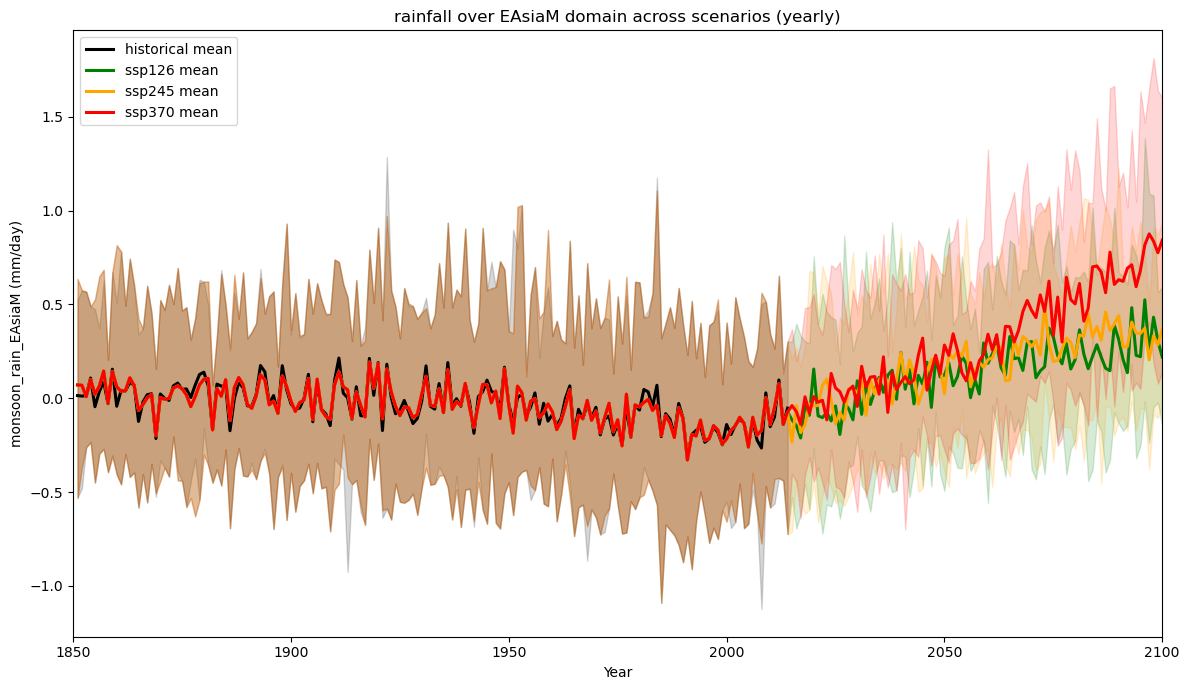

In [8]:
# exploration
# If you are investigating variable and don't know if it is a 1D time series or a 2D spatial map, you can use the `plot_smile_multiscenario` function in its simplest form. 

plot_smile_multiscenario(
    datasets_final_all,
    "monsoon_rain_EAsiaM" # put the variable that you would like to investgate here 
)

### time series

tas_global_avg_mon detected family: line
Available scenarios: ['historical', 'ssp126', 'ssp245', 'ssp370']


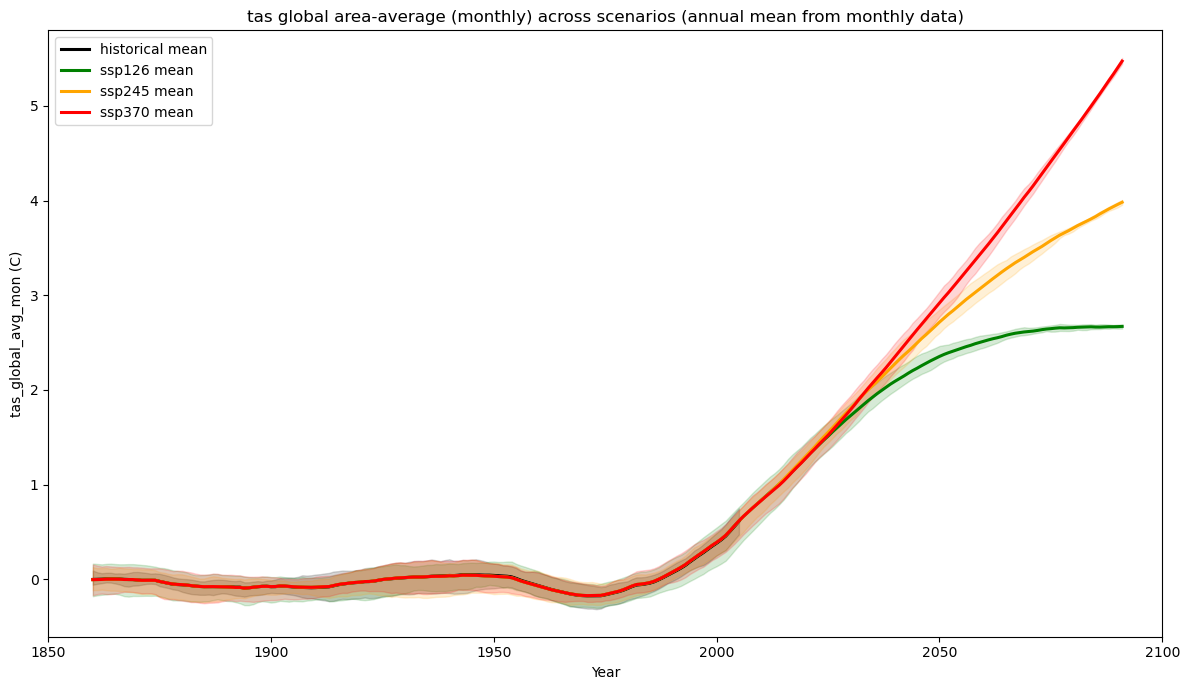

In [9]:
# monthly data
# get annual means first in monthly data before smoothing
plot_smile_multiscenario(
    datasets_final_all,
    "tas_global_avg_mon",
    temporal_mode="annual", 
    smooth_window=20     # unit of time: year
)

tas_global_avg_mon detected family: line
Available scenarios: ['historical', 'ssp126', 'ssp245', 'ssp370']


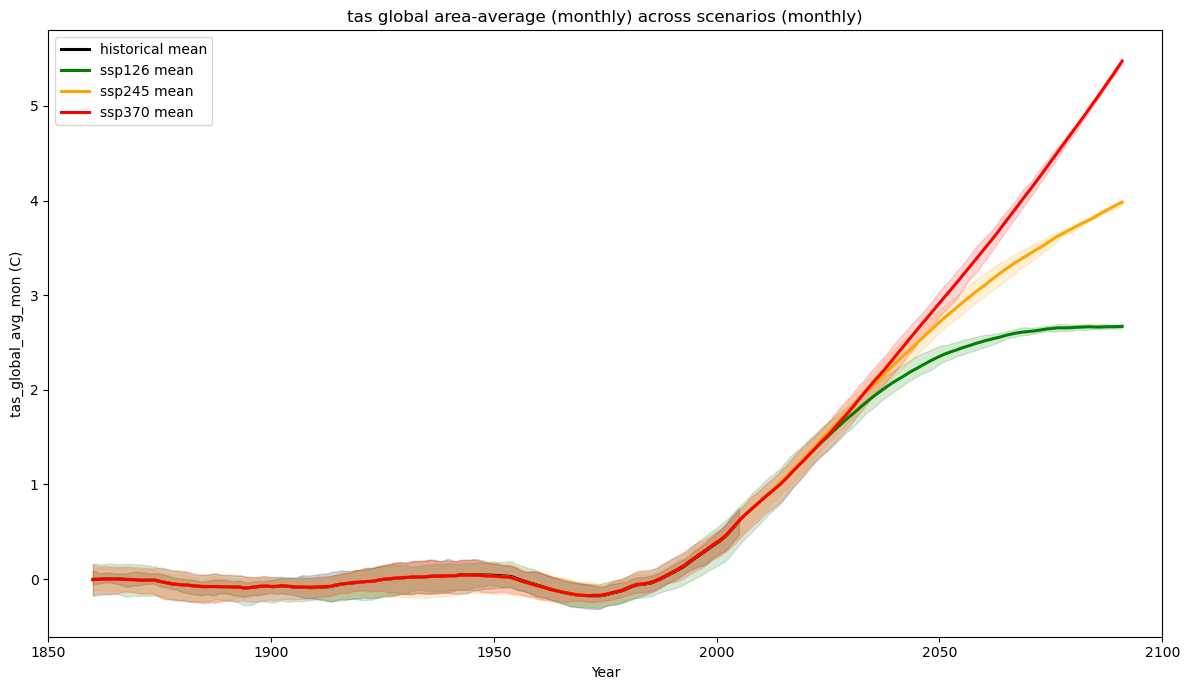

In [10]:
# monthly data
# keep monthly data in smoothing
plot_smile_multiscenario(
    datasets_final_all,
    "tas_global_avg_mon",
    temporal_mode="monthly",
    smooth_window=12*20    # unit of time: month

)

tas_global_avg_ann detected family: line
Available scenarios: ['historical', 'ssp126', 'ssp245', 'ssp370']


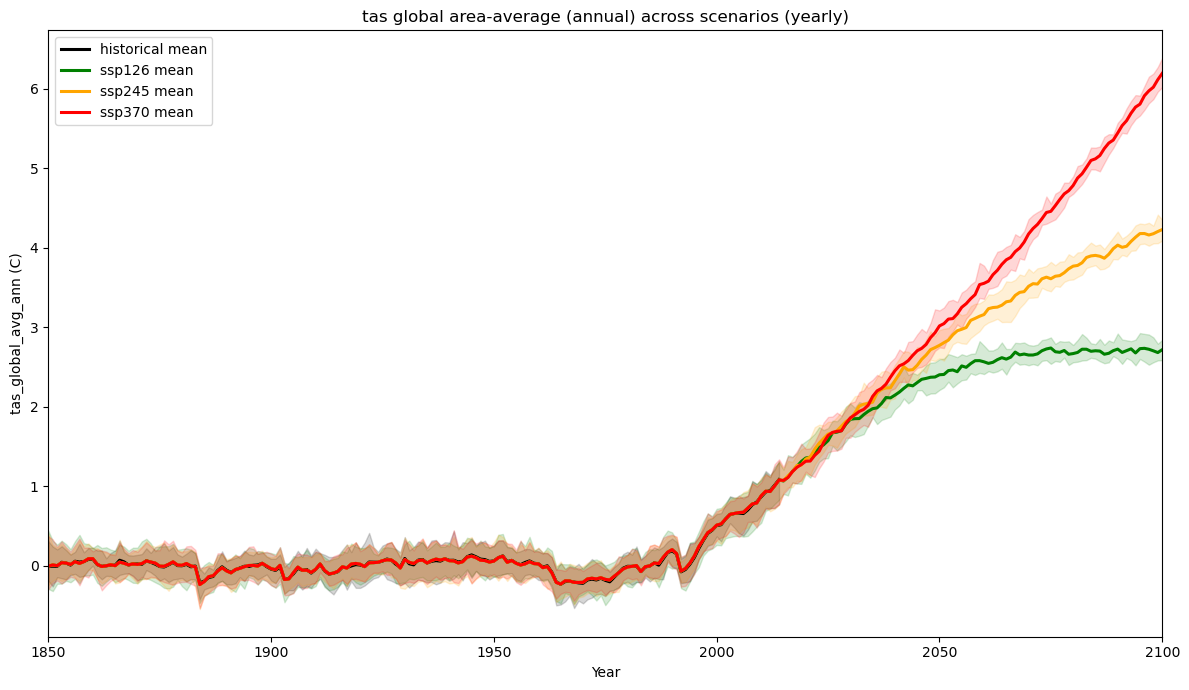

In [11]:
# annual data

plot_smile_multiscenario(
    datasets_final_all,
    "tas_global_avg_ann",
    temporal_mode="annual",
    smooth_window=1    # unit of time: year

)

### maps

pr_trends_ann detected family: field2d
Available scenarios: ['historical', 'ssp126', 'ssp245', 'ssp370']


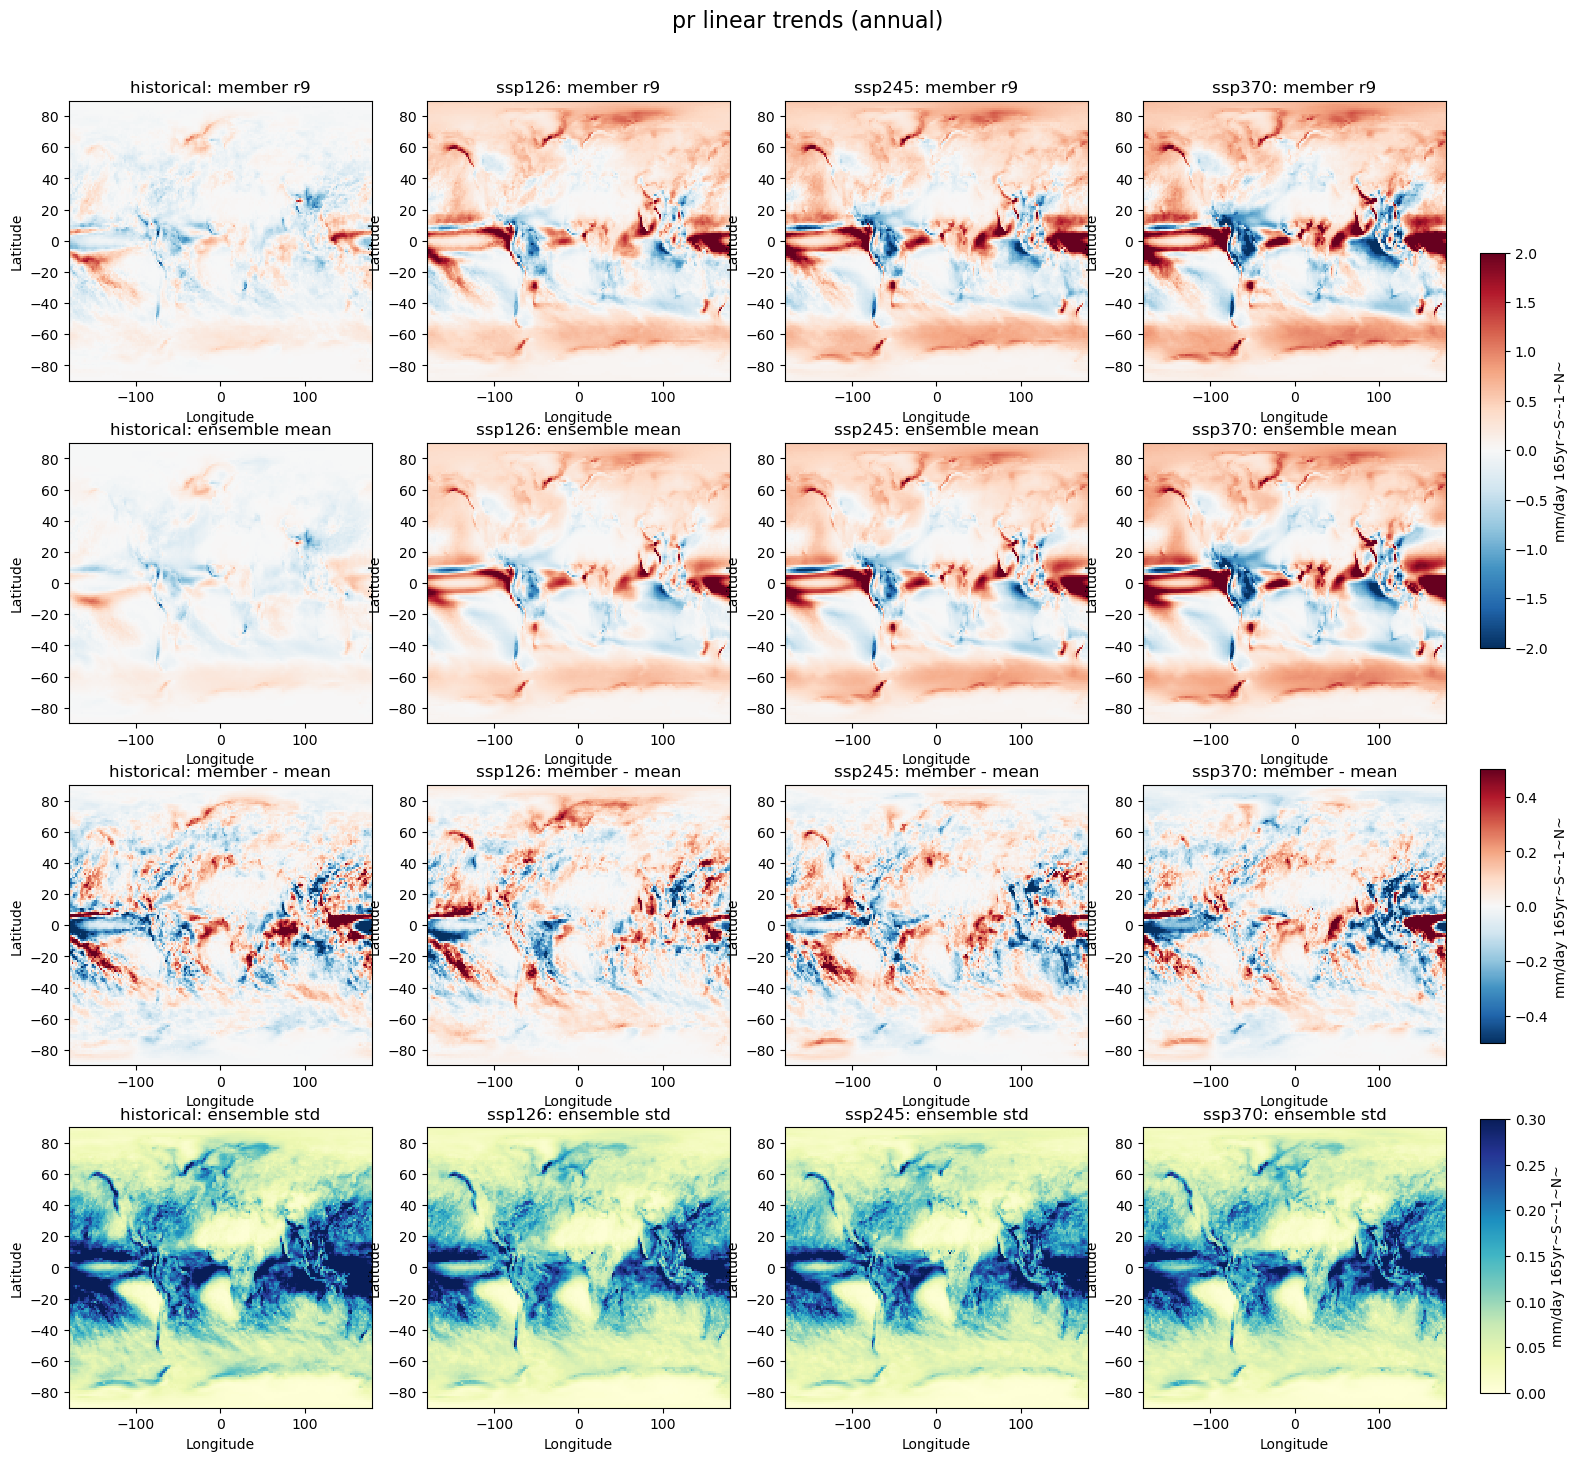

In [12]:
plot_smile_multiscenario(
    datasets_final_all,
    "pr_trends_ann",
    member_index=15,    # from 0-15 select ensemble member
    main_vmin=-2,       # upper bound of the first two rows
    main_vmax=2,        # lower bound of the first two rows
    diff_vmin=-0.5,     #upper bound of the third row
    diff_vmax=0.5,      #lower bound of the third row
    std_vmin=0,         #upper bound of the forth row 
    std_vmax=0.3        #lower bound of the forth row
)